# Bifurcation diagrams of the IBMF fixed points
Data produced on the cluster by `extract_bifurcation_summaries.py` (PBS scripts `run_extract_bifurcation_summaries.sh`
for the archives and `run_extract_bifurcation_runs.sh` for the dedicated runs): one row per distinct fixed point found by
`IBMF_LV_sequential_countFP`, for each graph (`seedgraph`), $\sigma$, $\mu$, $N$ and $n_{\rm init}$ (including the
intermediate checkpoints). Each point of the diagram is a distinct fixed point: abscissa $\mu$, colour the fraction of the
runs that reached it, ordinate one of the quantities that distinguish fixed points:
- `n0`, `n1`: abundance of species 0 or 1;
- `n_ave`: average abundance; `s2`: variance of the abundances;
- `n_ext`, `f_ext`: number and fraction of extinct species; `n_one`: number of species with abundance 1;
- `d_ref`: distance to the most frequent fixed point; `h_ref`: number of species whose extinction differs from it.

`n_ext`, `n_one`, `d_ref` and `h_ref` exist only in the summaries written by the current version of the program.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [2]:
path_data = "/run/media/david/Data/Research/Ecology/Results/IBMF/Counting_fixed_points/Bifurcation"    # downloaded csv.gz files
path_out = "/run/media/david/Data/Research/Ecology/Results/Plots_counting_fixed_points/bifurcation"
os.makedirs(path_out, exist_ok=True)


def set_style():
    plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "stix", "axes.linewidth": 1.2})


def format_axis(ax, tick_fontsize=14):
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_fontsize, length=3)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_fontsize, length=5)

In [3]:
# dedicated runs first: drop_duplicates keeps their rows, which have n_ext, n_one, d_ref, h_ref (absent in the archives)
files = sorted(glob.glob(f"{path_data}/bifurcation_*.csv.gz"), key=lambda f: ('bifurcation_runs_' not in f, f))
data = pd.concat([pd.read_csv(f, dtype={'eps': str, 'sigma': str, 'mu': str}) for f in files], ignore_index=True)
data['mu_value'] = data['mu'].astype(float)
data['s2'] = data['n_sq'] - data['n_ave']**2
if 'n_ext' in data:
    data['f_ext'] = data['n_ext'] / data['N']
data = data.drop_duplicates(subset=['sigma', 'seedgraph', 'N', 'ninitcond', 'mu', 'fp'])
print(f"{len(files)} files, {len(data)} fixed points")
pairs = (data.groupby(['sigma', 'seedgraph', 'N', 'ninitcond'])['mu'].nunique().rename('number of mu values')
         .reset_index())
pairs

4 files, 3019310 fixed points


,sigma,seedgraph,N,ninitcond,number of mu values
0,0.000,3,256,2048,2
1,0.000,3,512,2048,6
2,0.000,3,1024,2048,6
3,0.000,3,2048,2048,6
4,0.000,3,4096,2048,6
...,...,...,...,...,...
91,0.150,3,1024,2048,51
92,0.150,3,16384,256,61
93,0.150,3,16384,512,61
94,0.150,3,16384,1024,61


In [53]:
YLABELS = {'n0': r"$n_0$", 'n1': r"$n_1$", 'n_ave': r"$\bar n$", 's2': r"$s^2$", 'n_ext': "extinct species",
           'f_ext': "fraction of extinct species", 'n_one': r"species with $n_i=1$",
           'd_ref': r"distance to the most frequent fixed point", 'h_ref': "extinctions different from the most frequent"}


def plot_bifurcation(data, seedgraph, N, ninitcond, sigma='0.000', y='n0', ax=None, cmap='viridis', markersize=14,
                     label_fontsize=20, title_fontsize=18, colorbar=True, save_to=None, mu_range=[-np.inf, np.inf]):
    """Distinct fixed points: y vs mu, coloured by the fraction of the runs that reached each of them."""
    sub = data[(data['sigma'] == sigma) & (data['seedgraph'] == seedgraph) & (data['N'] == N)
               & (data['ninitcond'] == ninitcond) & (data['mu_value'] >= mu_range[0]) & (data['mu_value'] <= mu_range[1])]
    sub = sub.sort_values('fraction')          # the most frequent fixed points are drawn on top
    set_style()
    new_figure = ax is None
    if new_figure:
        fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
        fig.subplots_adjust(left=0.14, bottom=0.14, right=0.97, top=0.92)
    norm = LogNorm(vmin=1.0 / ninitcond, vmax=1.0)
    if y == 'n_ext' or y == 'h_ref':
        normalization = N
    else:
        normalization = 1
    sc = ax.scatter(sub['mu_value'], sub[y] / normalization, c=sub['fraction'], cmap=cmap, norm=norm, s=markersize, lw=0)
    ax.set_xlabel(r"$\mu$", fontsize=label_fontsize)
    ax.set_ylabel(YLABELS.get(y, y), fontsize=label_fontsize if y in ('n0', 'n1', 'n_ave', 's2') else label_fontsize - 6)
    ax.set_title(rf"$\sigma={float(sigma):.2f}$, $N={N}$, $n_{{\rm init}}={ninitcond}$",
                 fontsize=title_fontsize)
    format_axis(ax)
    if colorbar:
        cb = plt.colorbar(sc, ax=ax)
        cb.set_label("fraction of runs", fontsize=label_fontsize - 4)
        cb.ax.tick_params(labelsize=12)
    if new_figure:
        if save_to is not None:
            fig.savefig(save_to)
        plt.show()
    return sc

## $\sigma=0$

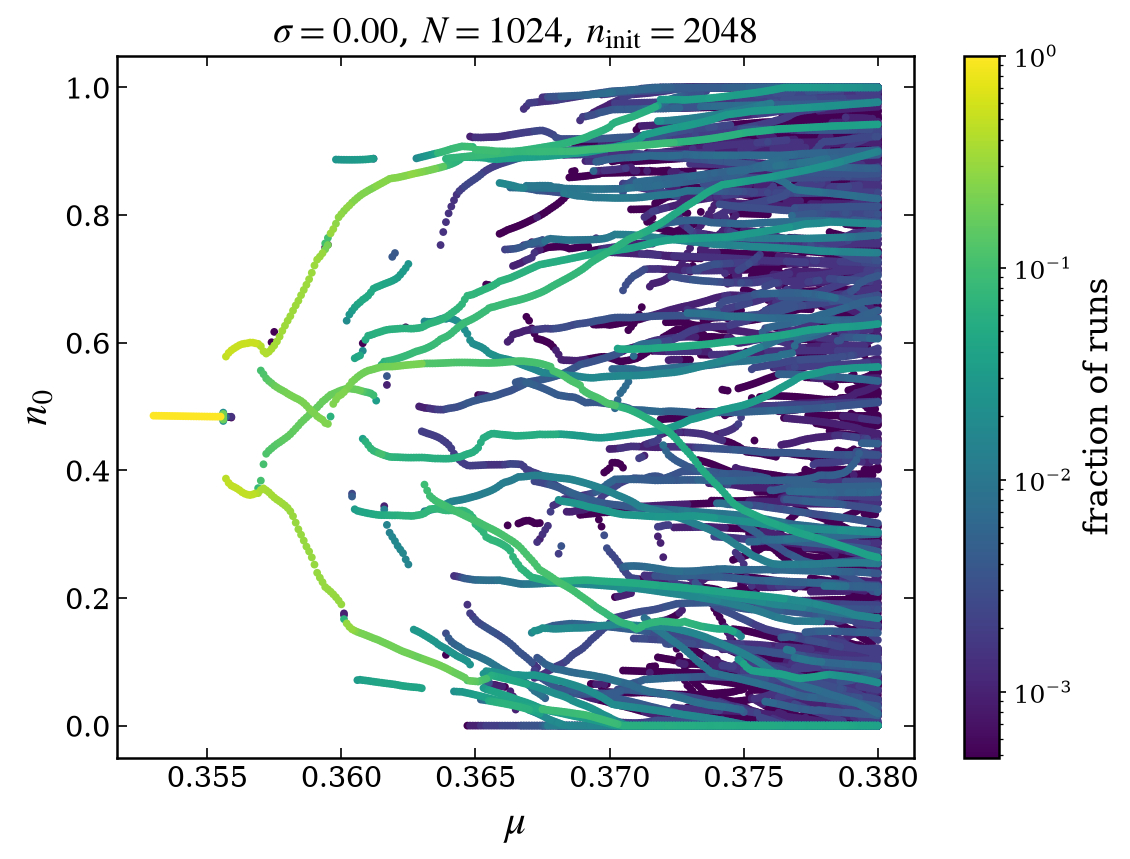

In [40]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.000'
g = 14
N = 1024
ninit = 2048
y_plot = 'n0'
mu_range = [0.35, 0.38]
save_to = f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_{y_plot}.png"
plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, mu_range=mu_range, save_to=save_to)

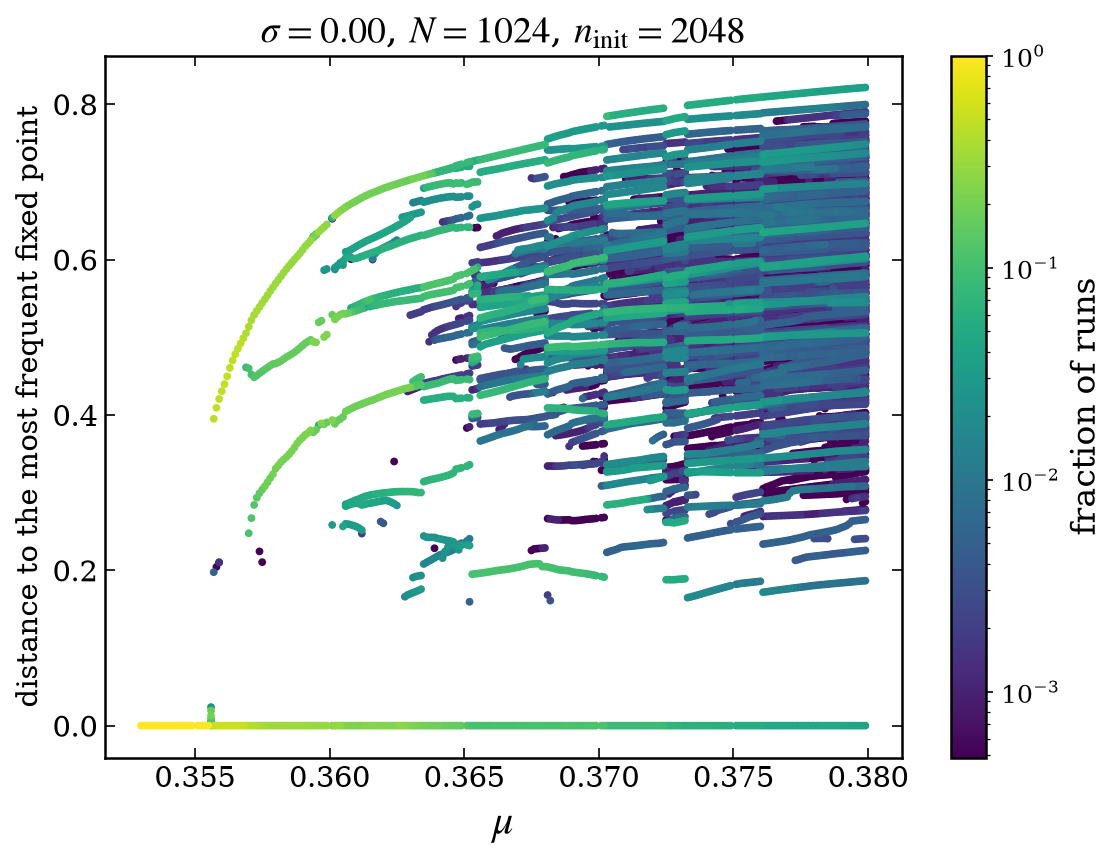

In [41]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.000'
g = 14
N = 1024
ninit = 2048
y_plot = 'd_ref'
mu_range = [0.35, 0.38]
save_to = f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_{y_plot}.png"
plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, mu_range=mu_range, save_to=None)

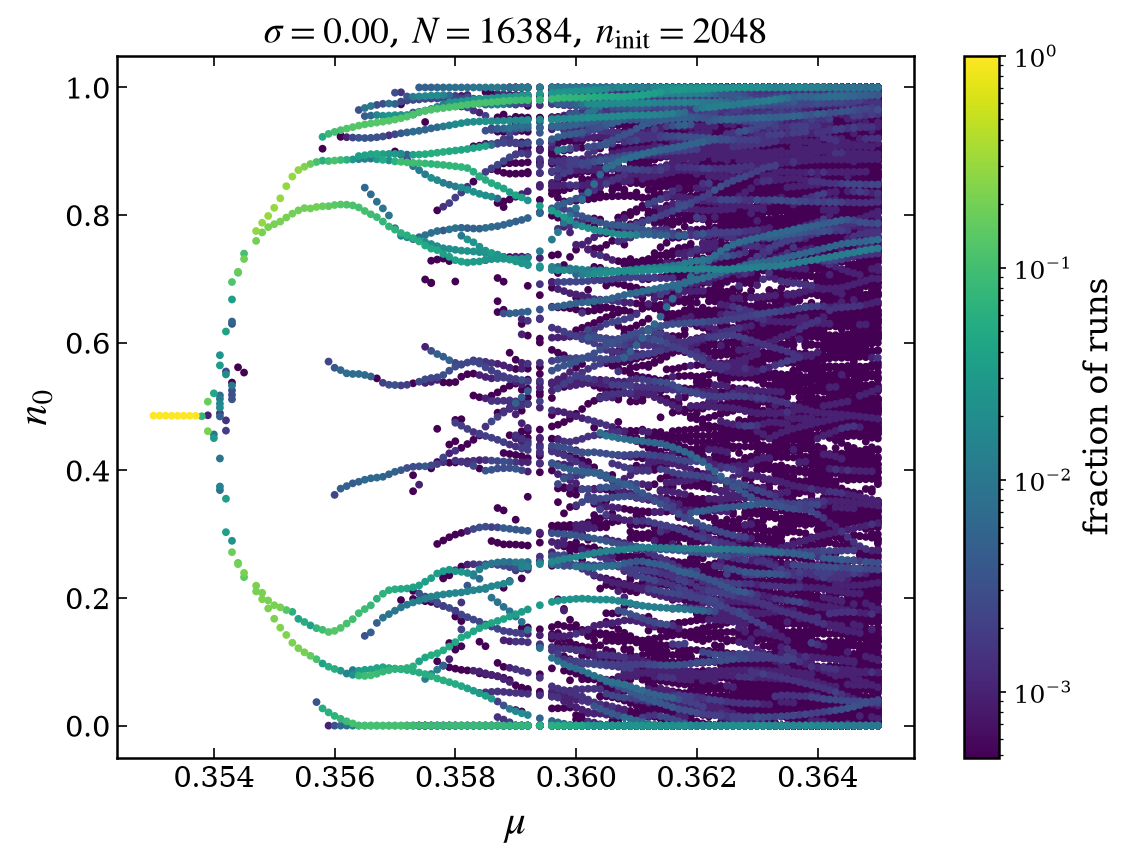

In [42]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.000'
g = 14
N = 16384
ninit = 2048
y_plot = 'n0'
mu_range = [0.35, 0.365]
save_to = f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_{y_plot}.png"
plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, mu_range=mu_range, save_to=None)

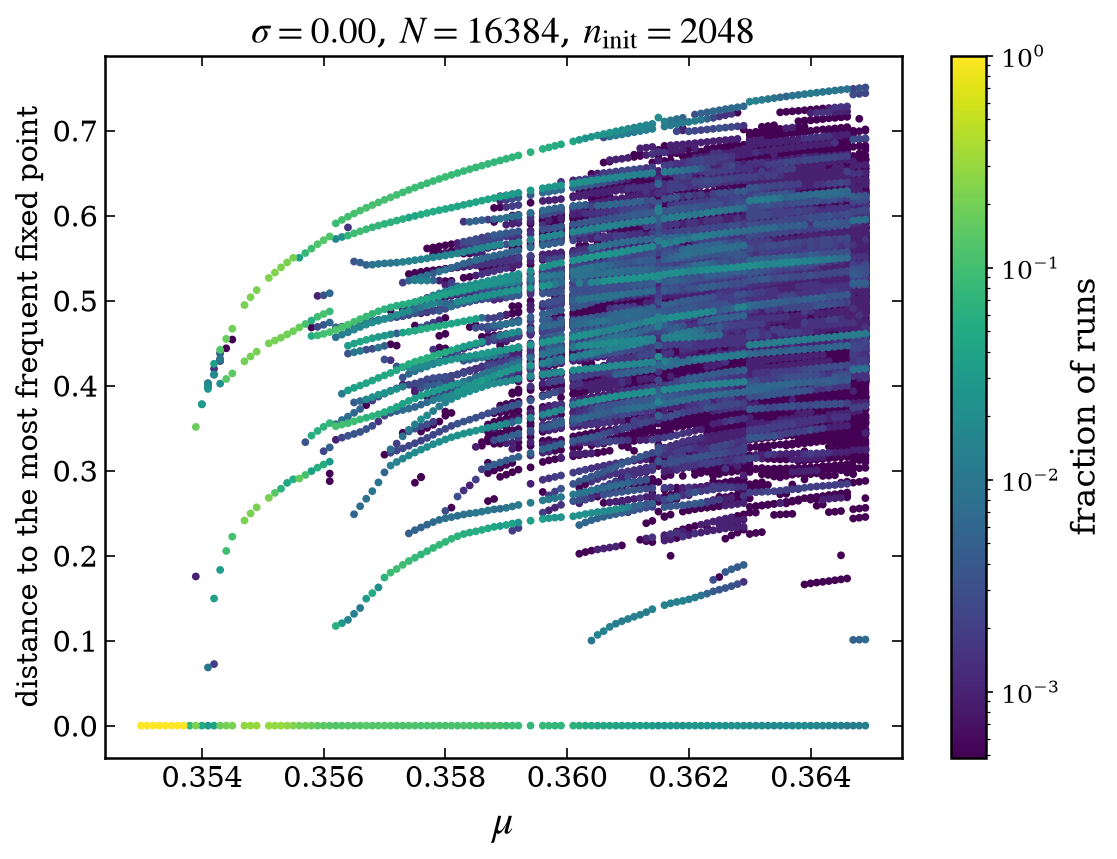

In [43]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.000'
g = 14
N = 16384
ninit = 2048
y_plot = 'd_ref'
mu_range = [0.35, 0.365]
save_to = f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_{y_plot}.png"
plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, mu_range=mu_range, save_to=None)

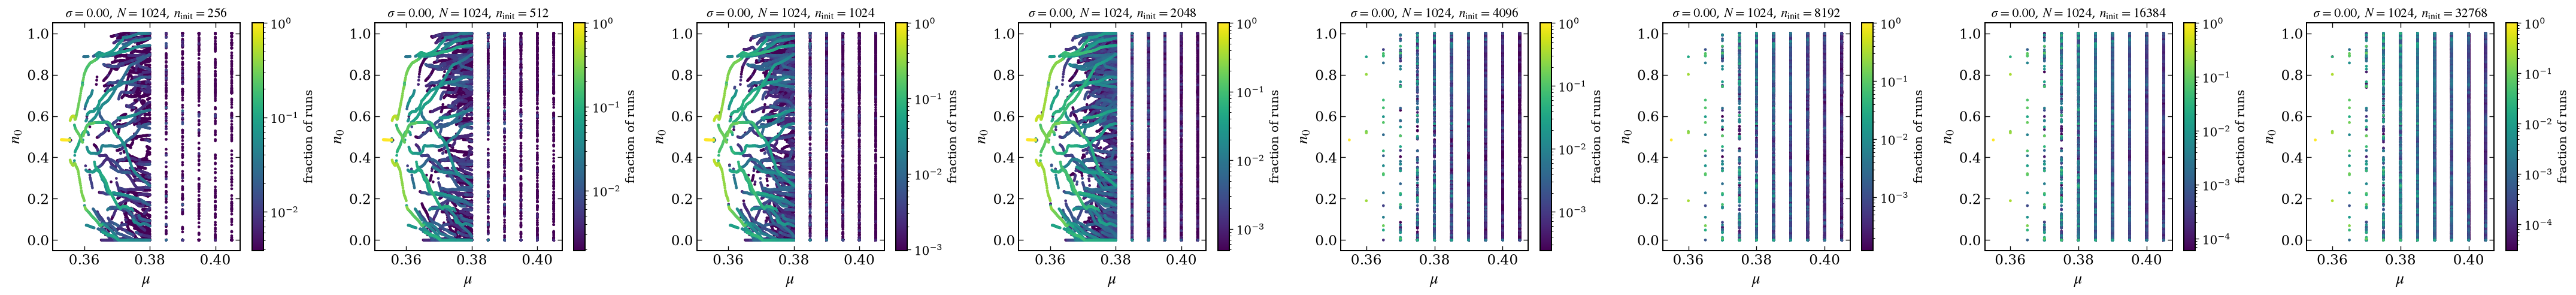

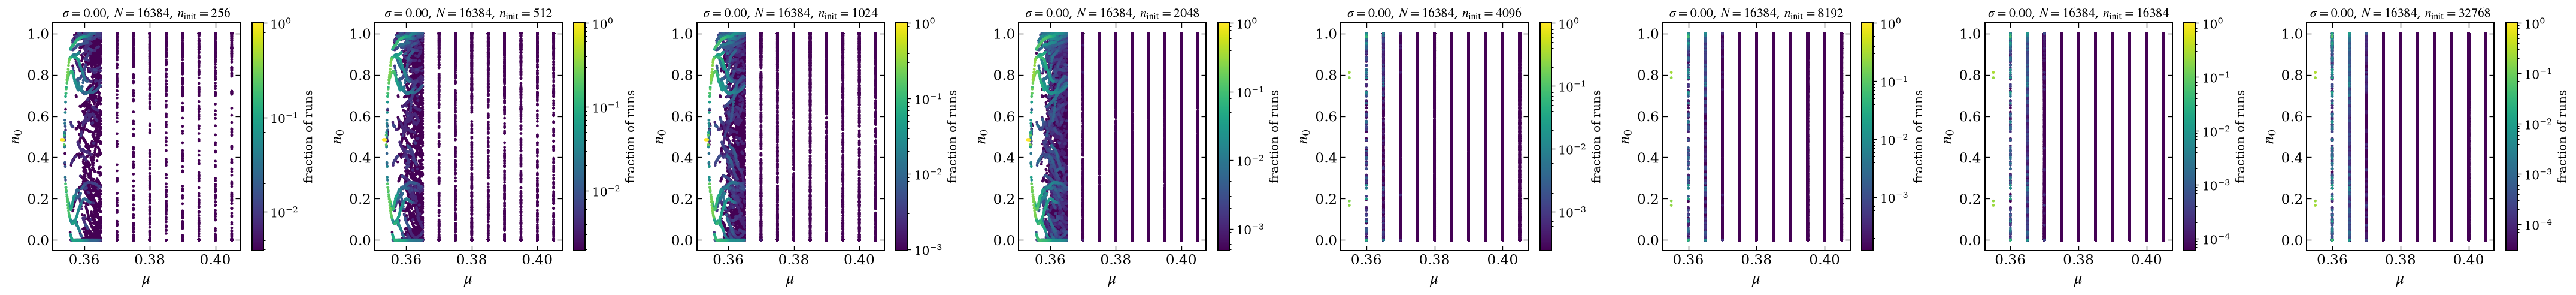

In [44]:
# comparison of different n_init at fixed N (one row of panels per N)
# for g in sorted(pairs['seedgraph'].unique()):
    # for N in sorted(pairs[pairs['seedgraph'] == g]['N'].unique()):
for g in [14]:
    for N in [1024, 16384]:
        ninits = sorted(pairs[(pairs['seedgraph'] == g) & (pairs['N'] == N)]['ninitcond'].unique())
        set_style()
        fig, axs = plt.subplots(1, len(ninits), figsize=(4.5 * len(ninits), 4.2), dpi=120, squeeze=False)
        for ax, ninit in zip(axs[0], ninits):
            plot_bifurcation(data, g, N, ninit, ax=ax, label_fontsize=16, title_fontsize=13, markersize=8)
        fig.tight_layout()
        fig.savefig(f"{path_out}/bifurcation_sigma_0.000_seedgraph_{g}_N_{N}_all_ninit.png")
        plt.show()

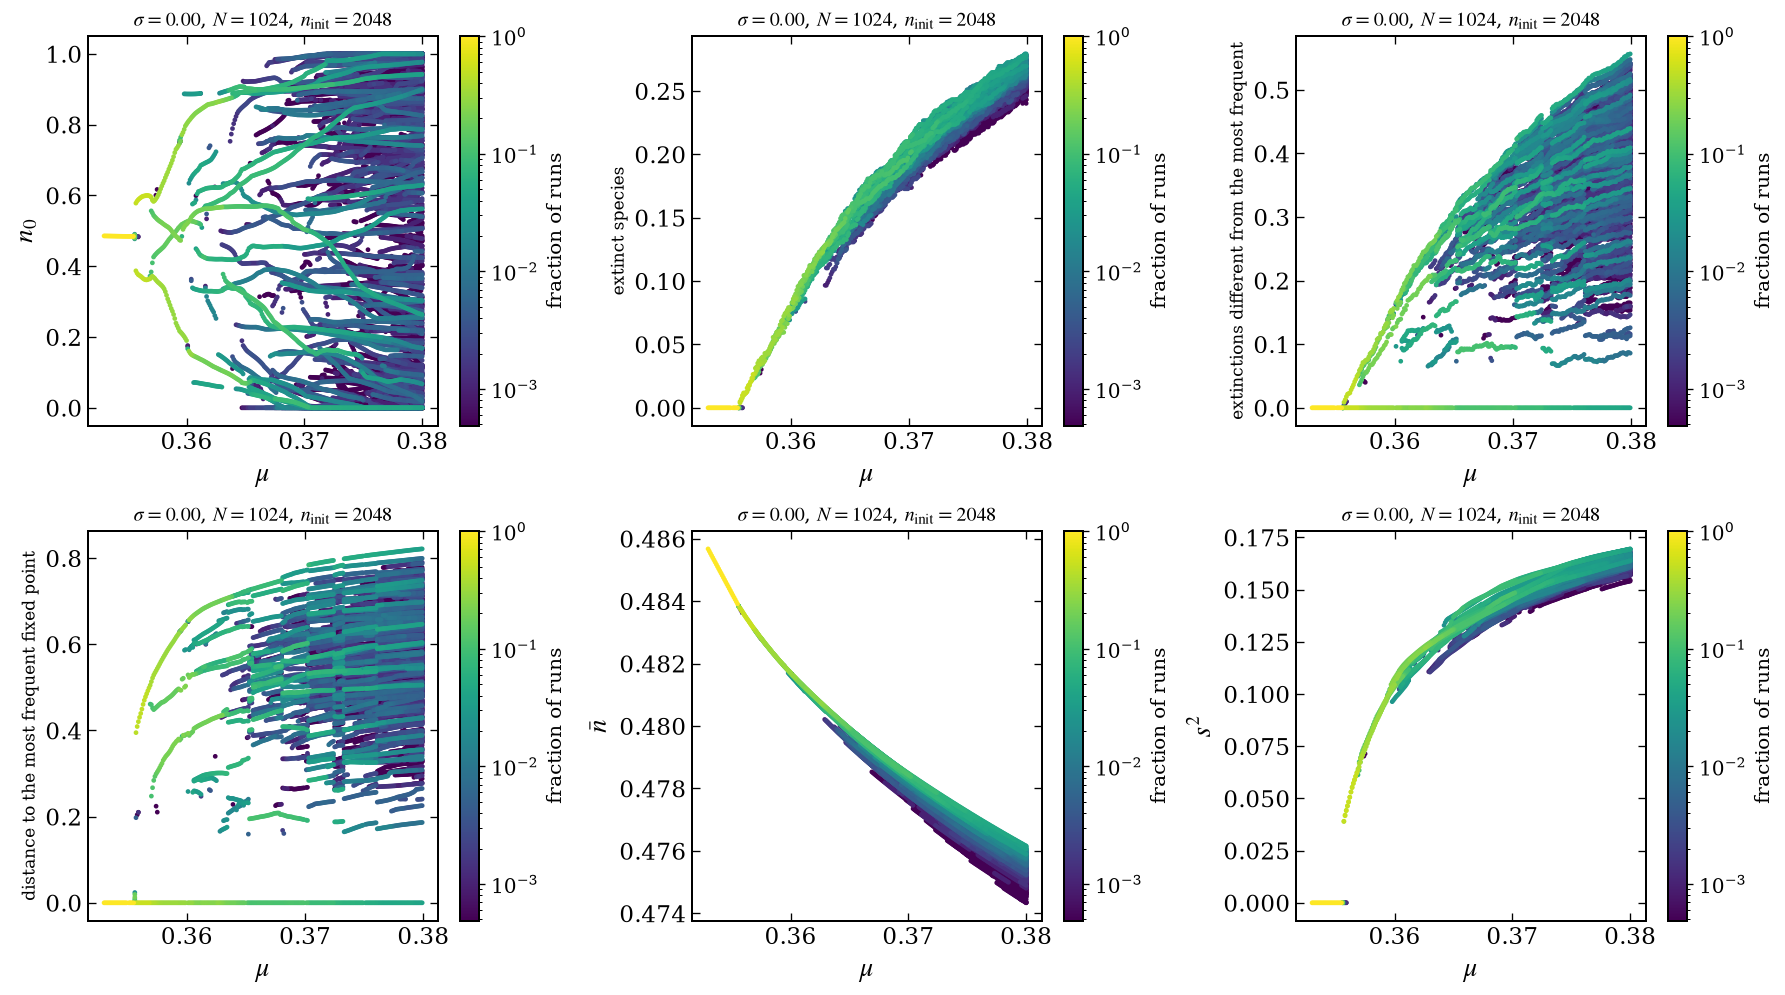

In [54]:
# the same fixed points with different quantities on the vertical axis
sigma, g, N, ninit = '0.000', 14, 1024, 2048
mu_range = [0.35, 0.38]
ys = ['n0', 'n_ext', 'h_ref', 'd_ref', 'n_ave', 's2']
set_style()
fig, axs = plt.subplots(2, 3, figsize=(15, 8.4), dpi=120)
for ax, y in zip(axs.flat, ys):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_all_y.png")
plt.show()

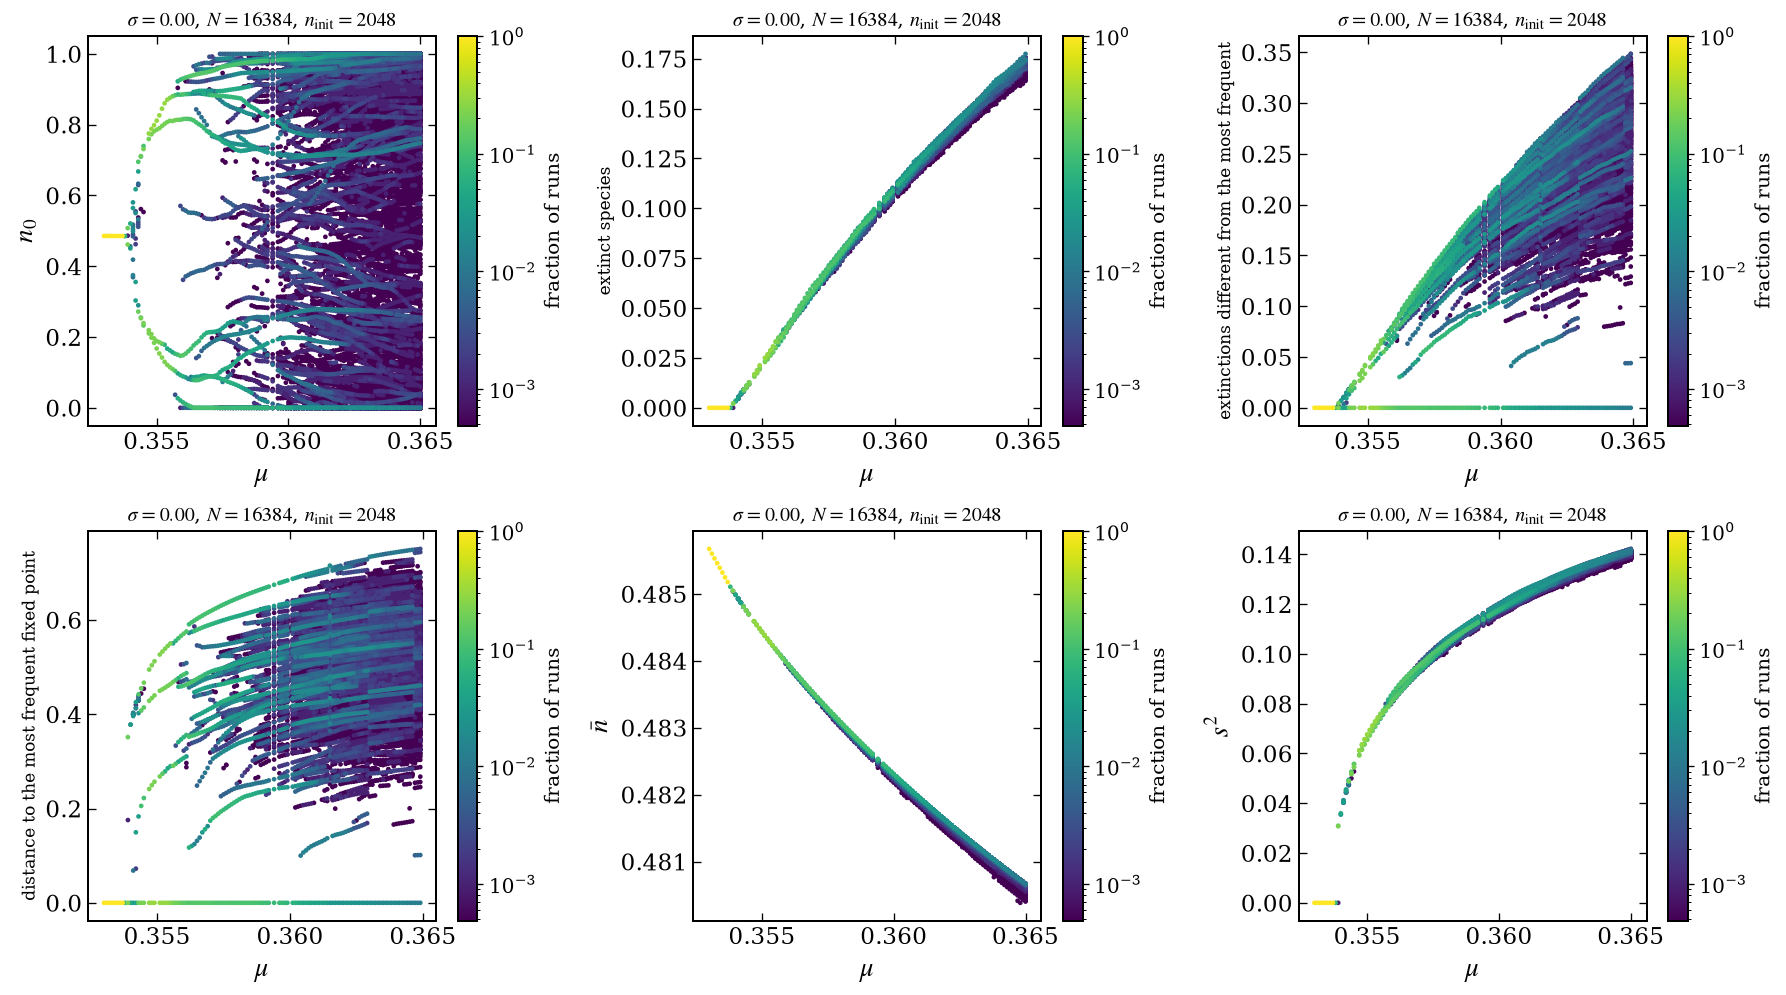

In [55]:
# the same fixed points with different quantities on the vertical axis
sigma, g, N, ninit = '0.000', 14, 16384, 2048
mu_range = [0.35, 0.365]
ys = ['n0', 'n_ext', 'h_ref', 'd_ref', 'n_ave', 's2']
set_style()
fig, axs = plt.subplots(2, 3, figsize=(15, 8.4), dpi=120)
for ax, y in zip(axs.flat, ys):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_all_y.png")
plt.show()

## $\sigma=0.15$

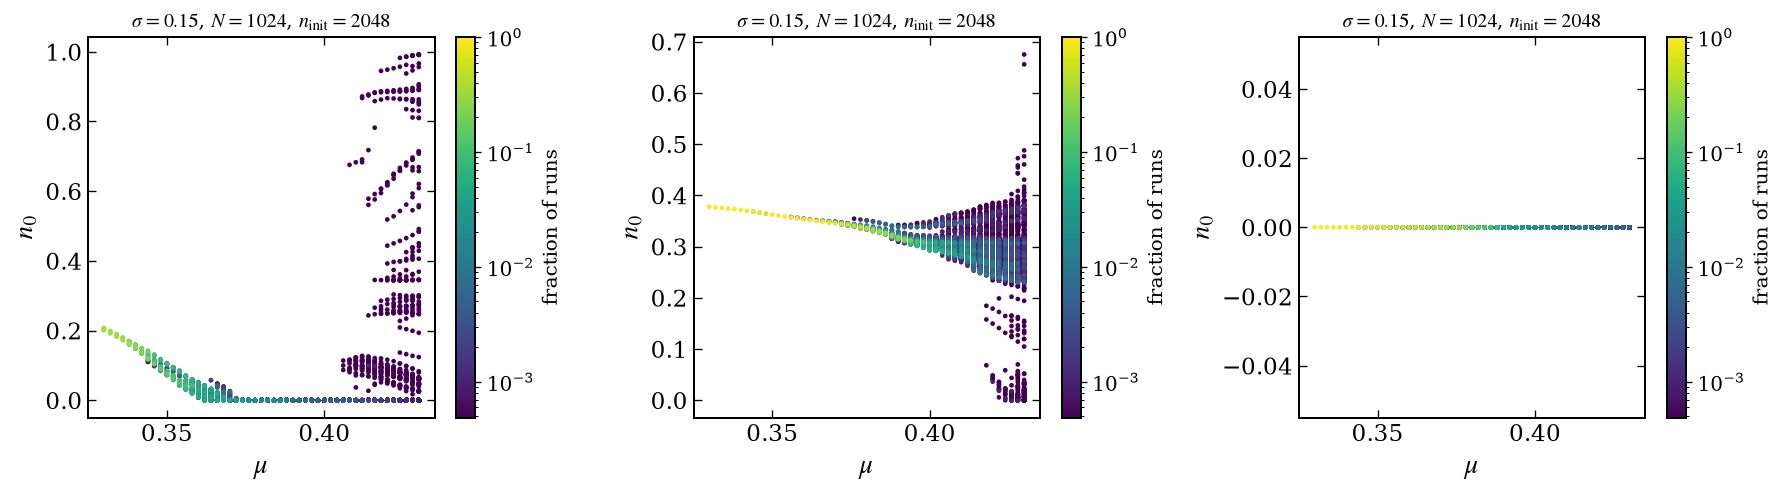

In [47]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.150'
N = 1024
g_seeds = [1, 2, 3]
ninit = 2048
y_plot = 'n0'
mu_range = [0.31, 0.43]
set_style()
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)
for ax, g in zip(axs.flat, g_seeds):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_ngraphs_{len(g_seeds)}_N_{N}_ninit_{ninit}_{y_plot}.png")
plt.show()

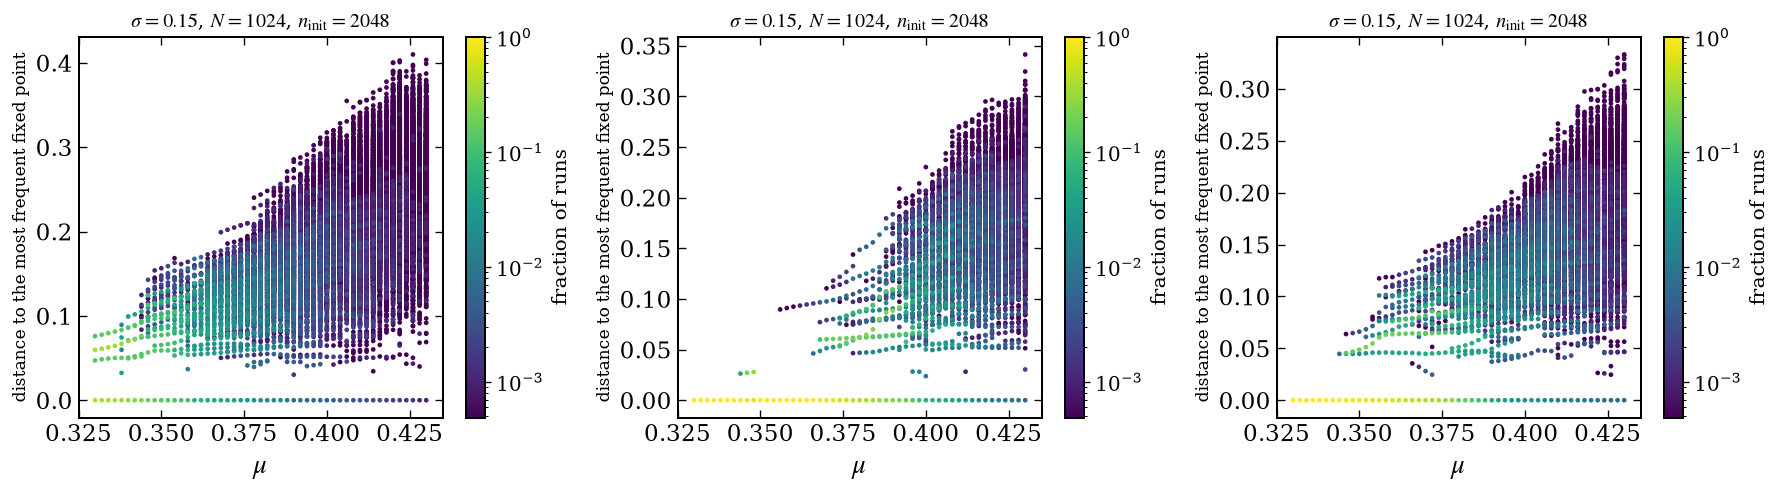

In [48]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.150'
N = 1024
g_seeds = [1, 2, 3]
ninit = 2048
y_plot = 'd_ref'
mu_range = [0.31, 0.43]
set_style()
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)
for ax, g in zip(axs.flat, g_seeds):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_ngraphs_{len(g_seeds)}_N_{N}_ninit_{ninit}_{y_plot}.png")
plt.show()

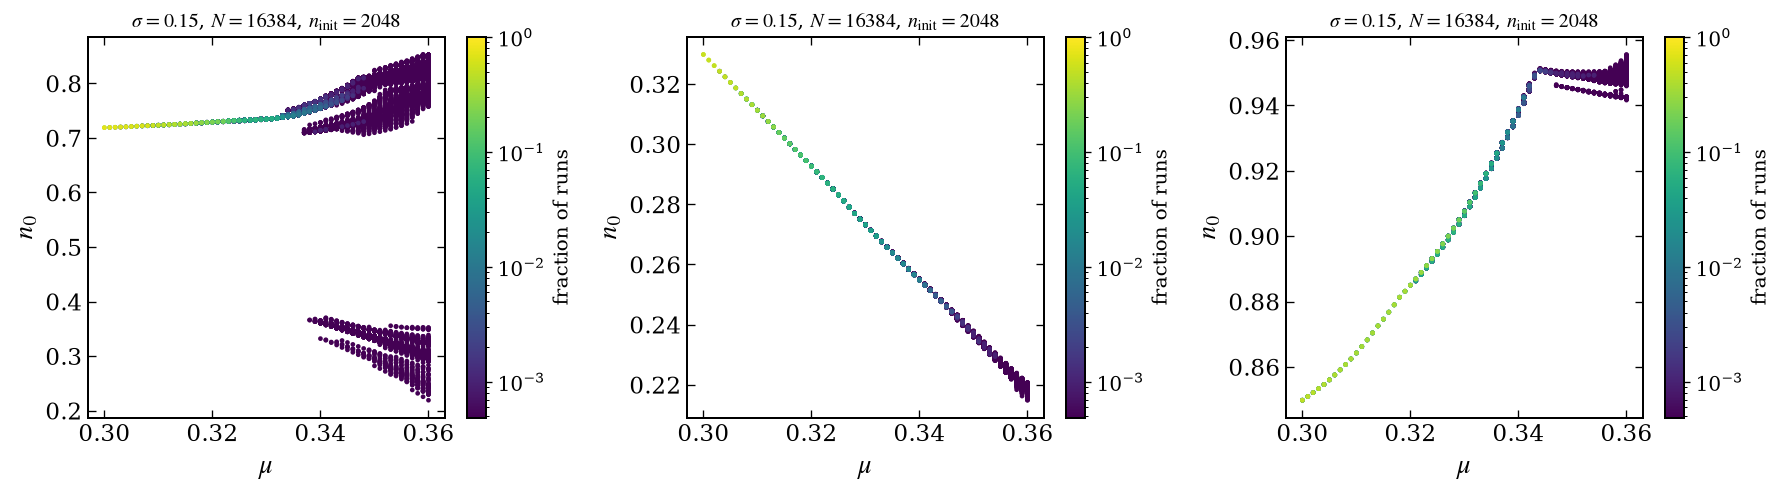

In [49]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.150'
N = 16384
g_seeds = [1, 2, 3]
ninit = 2048
y_plot = 'n0'
mu_range = [0.29, 0.43]
set_style()
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)
for ax, g in zip(axs.flat, g_seeds):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_ngraphs_{len(g_seeds)}_N_{N}_ninit_{ninit}_{y_plot}.png")
plt.show()

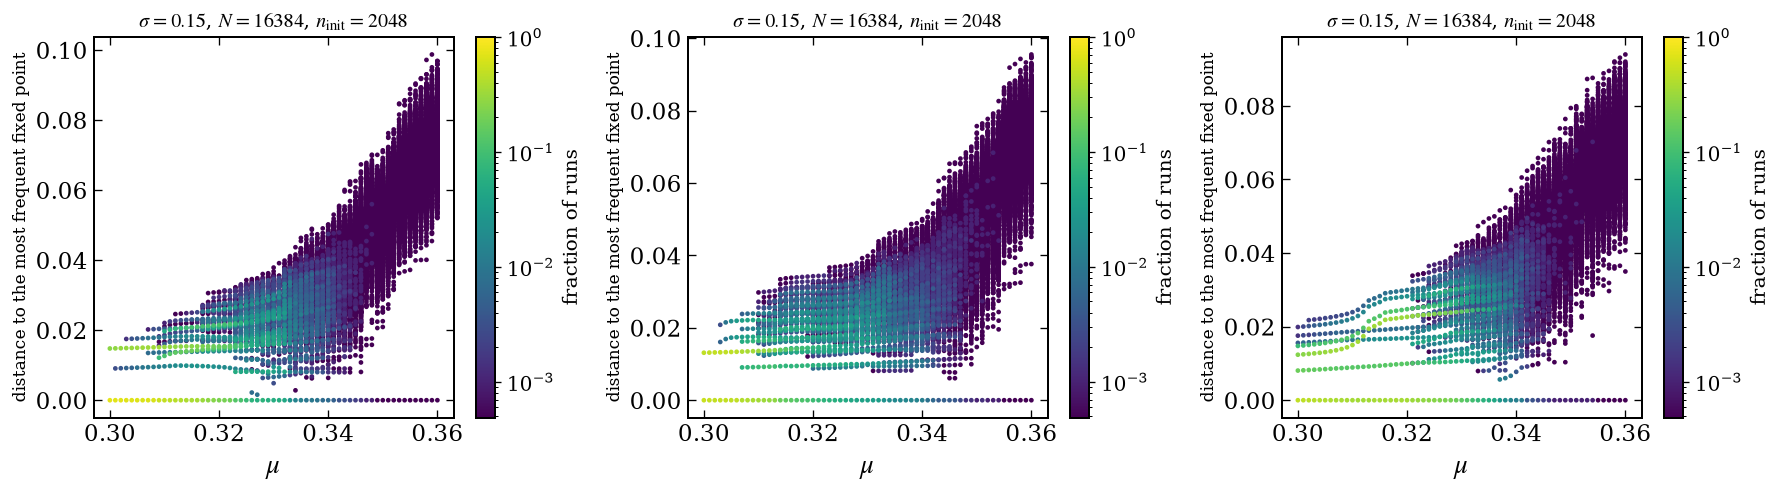

In [50]:
# one figure for each pair (N, n_init) of each graph
sigma = '0.150'
N = 16384
g_seeds = [1, 2, 3]
ninit = 2048
y_plot = 'd_ref'
mu_range = [0.29, 0.43]
set_style()
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)
for ax, g in zip(axs.flat, g_seeds):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y_plot, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_ngraphs_{len(g_seeds)}_N_{N}_ninit_{ninit}_{y_plot}.png")
plt.show()

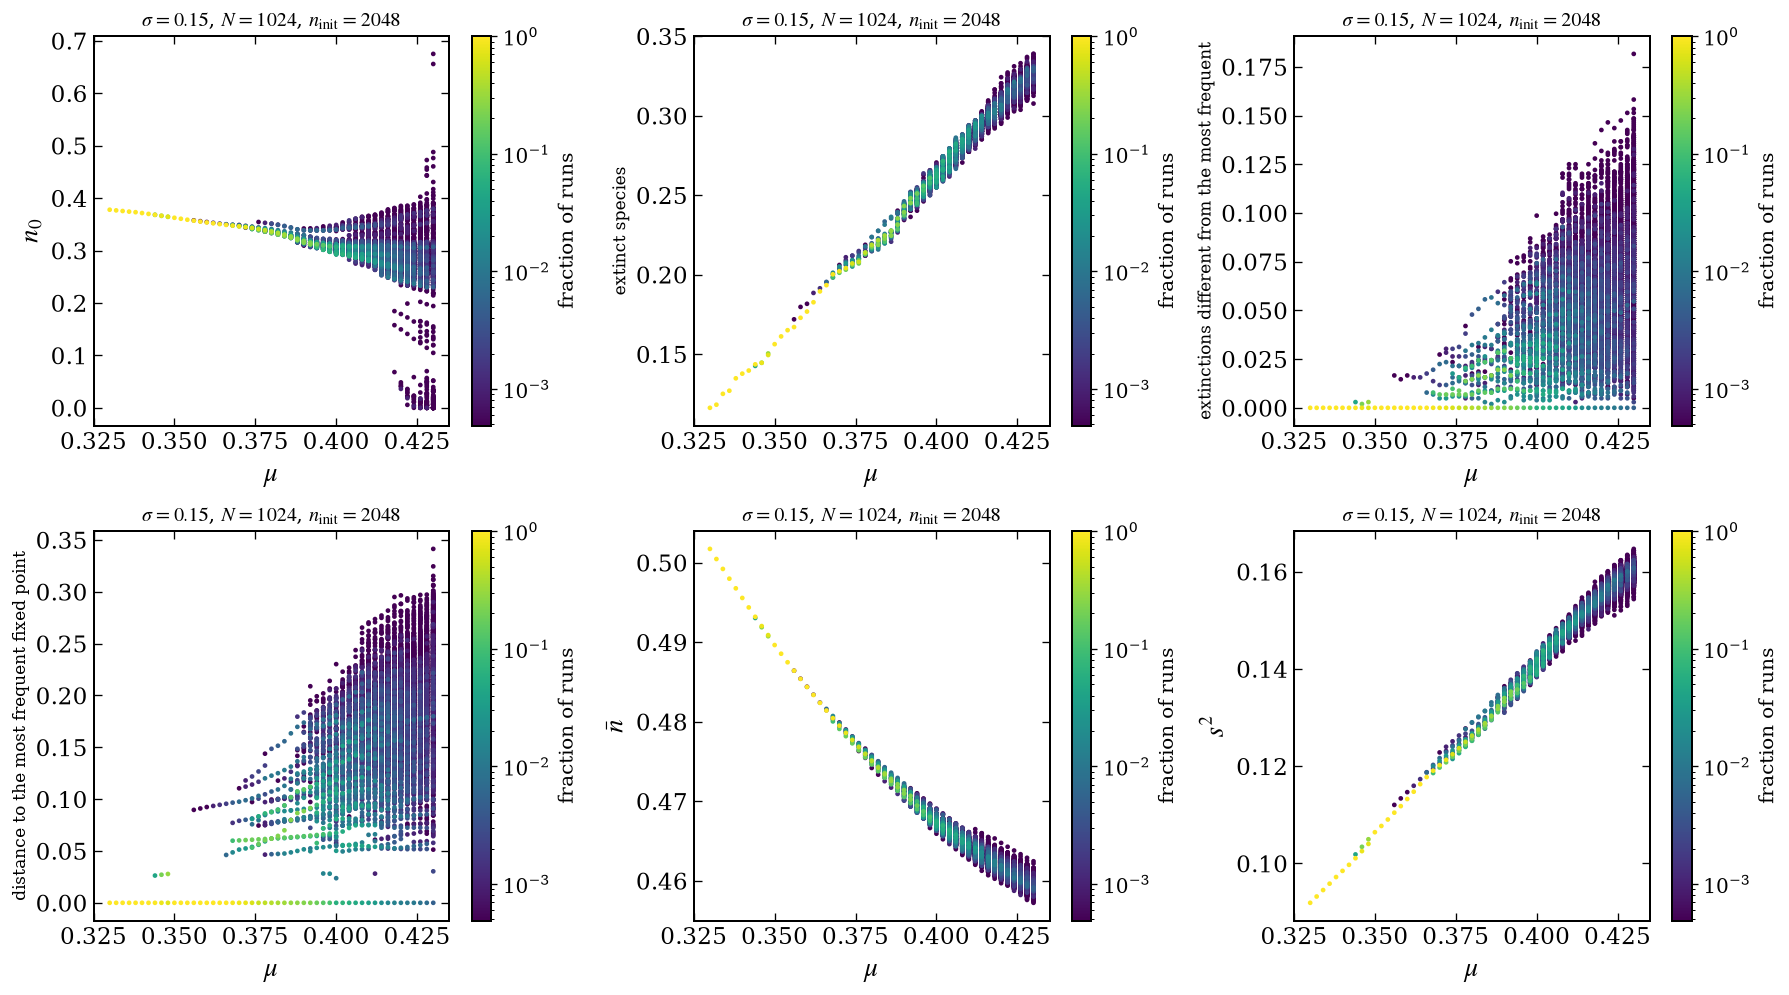

In [56]:
# the same fixed points with different quantities on the vertical axis
sigma, g, N, ninit = '0.150', 2, 1024, 2048
mu_range = [0.31, 0.43]
ys = ['n0', 'n_ext', 'h_ref', 'd_ref', 'n_ave', 's2']
set_style()
fig, axs = plt.subplots(2, 3, figsize=(15, 8.4), dpi=120)
for ax, y in zip(axs.flat, ys):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_all_y.png")
plt.show()

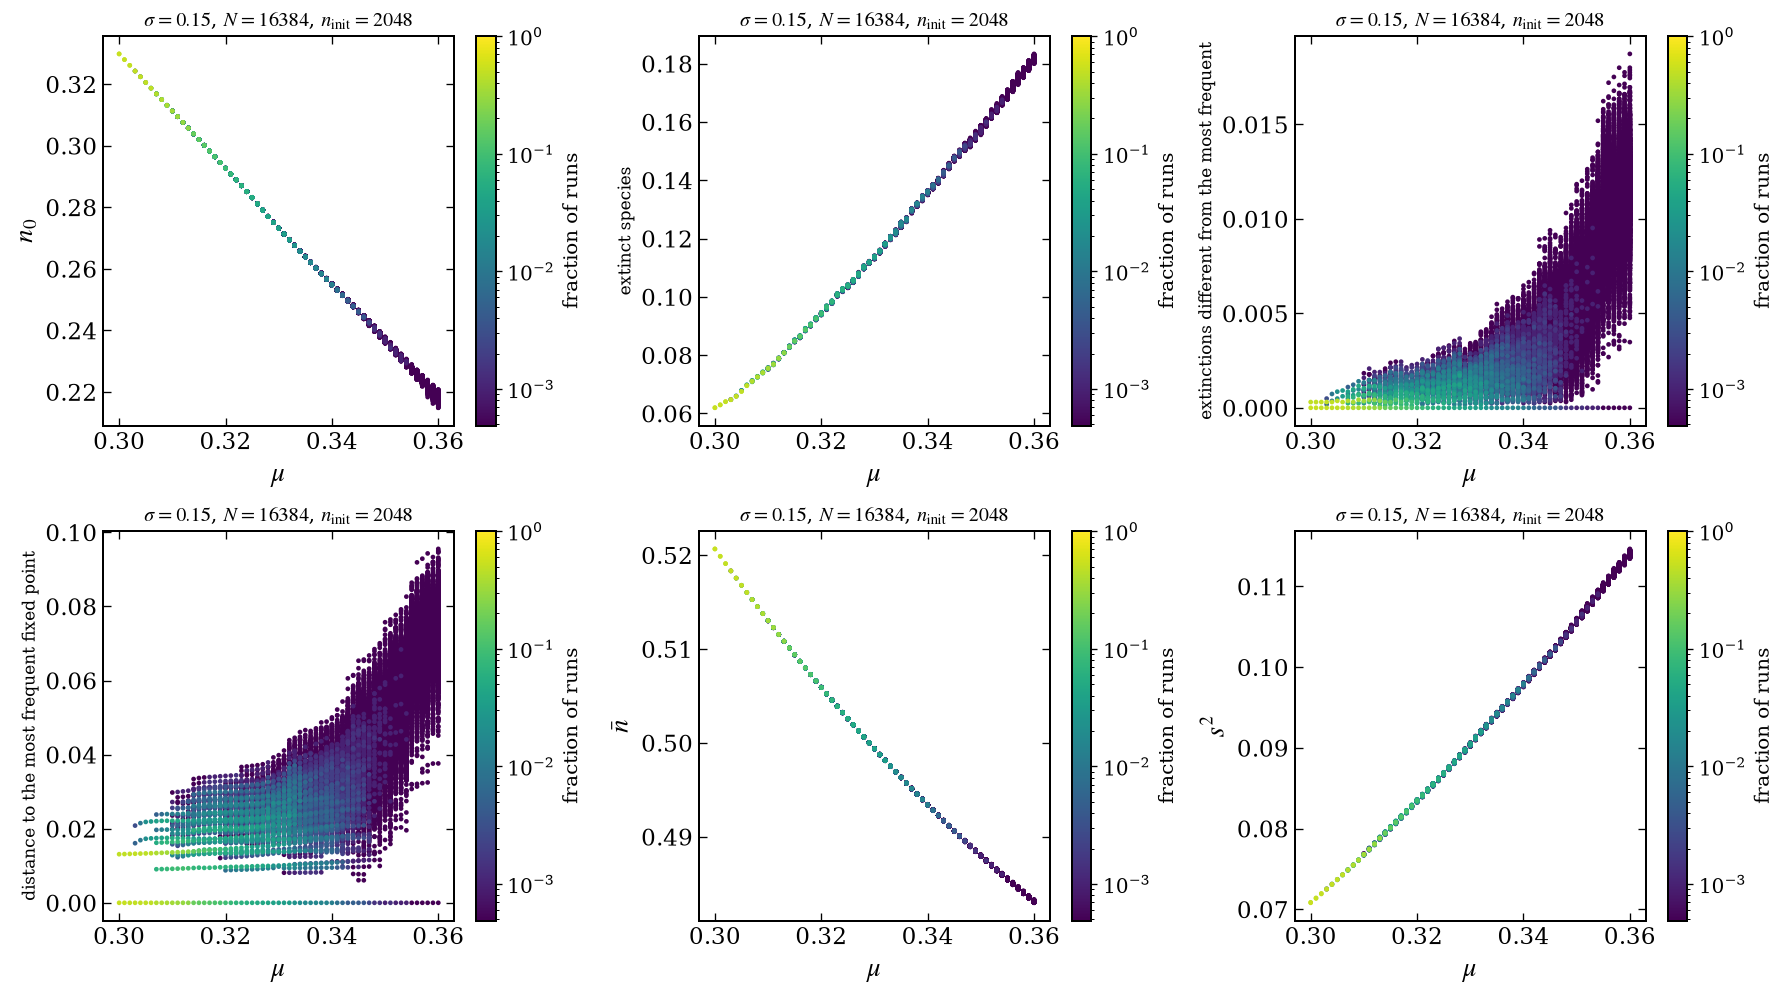

In [57]:
# the same fixed points with different quantities on the vertical axis
sigma, g, N, ninit = '0.150', 2, 16384, 2048
mu_range = [0.29, 0.43]
ys = ['n0', 'n_ext', 'h_ref', 'd_ref', 'n_ave', 's2']
set_style()
fig, axs = plt.subplots(2, 3, figsize=(15, 8.4), dpi=120)
for ax, y in zip(axs.flat, ys):
    plot_bifurcation(data, g, N, ninit, sigma=sigma, y=y, ax=ax, label_fontsize=16, 
                     title_fontsize=12, markersize=8, mu_range=mu_range)
fig.tight_layout()
fig.savefig(f"{path_out}/bifurcation_sigma_{sigma}_seedgraph_{g}_N_{N}_ninit_{ninit}_all_y.png")
plt.show()